# F23: Endelig volum-metode i 1D -- en stav uten kildeledd

Denne notatboken hører til **F23** og kompendiets §3.4 («Numeriske metoder: Endeligvolum-metode») og første eksempel i §3.5 («Varmeledning i en stav uten kildeledd»).

Ideen i endelig volum-metoden (EVM) er å skrive opp **bevaringsloven for hver celle**: varmen som strømmer inn gjennom cellens flater, minus varmen som strømmer ut, er lik varmen som produseres i cellen. For en stav uten varmekilde betyr det bare at *fluksen inn = fluksen ut* for hver celle. Diskretisert gir det én ligning per celle,
$$
a_P T_P = a_W T_W + a_E T_E + S^u, \qquad a_P = a_W + a_E - S_P,
$$
og et tridiagonalt ligningssystem vi kan løse.

Vi går gjennom stav-eksempelet steg for steg, lager så en generell funksjon, og sjekker til slutt at metoden faktisk *bevarer* varmen.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Problemet

En stav med lengde $L=0.5$ m, varmeledningsevne $\kappa = 1000$ W/(m K) og tverrsnittsareal $A = 10\cdot 10^{-3}$ m$^2$. Venstre ende holdes på $T_V = 100\,^\circ$C og høyre ende på $T_H = 500\,^\circ$C. Det er ingen varmekilde, så temperaturen oppfyller
$$
\frac{d}{dx}\left(\kappa \frac{dT}{dx}\right) = 0, \qquad T(0)=T_V, \quad T(L)=T_H .
$$
Den eksakte løsningen er en rett linje, $T(x) = T_V + (T_H-T_V)\,x/L = 100 + 800x$.

In [2]:
L = 0.5          # lengde [m]
kappa = 1000.0   # varmeledningsevne [W/(m K)]
A = 10e-3        # tverrsnittsareal [m^2]
T_V, T_H = 100.0, 500.0   # randtemperaturer [grader C]

def T_eksakt(x):
    return T_V + (T_H - T_V) * x / L

## 2. Gitteret: noder midt i cellene

Vi deler staven i $N=5$ like store kontrollvolumer (celler) med bredde $\delta x = L/N = 0.1$ m.

Legg merke til forskjellen fra endelige differanser: **flatene** (cellegrensene) ligger i $x=0, 0.1, \ldots, 0.5$, og **nodene** -- der vi regner ut temperaturen -- ligger *midt i* hver celle, i $x = 0.05, 0.15, \ldots, 0.45$. Randene $V$ og $H$ er altså celleflater, ikke noder. Den ytterste noden ligger derfor bare $\delta x/2$ fra randen.

Flater: [0.  0.1 0.2 0.3 0.4 0.5]
Noder:  [0.05 0.15 0.25 0.35 0.45]


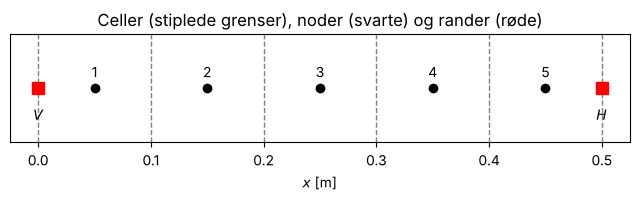

In [3]:
N = 5
dx = L / N
flater = np.linspace(0, L, N + 1)        # cellegrenser
noder = 0.5 * (flater[:-1] + flater[1:])  # midtpunktene

print("Flater:", flater)
print("Noder: ", noder)

fig, ax = plt.subplots(figsize=(8, 1.4))
for xf in flater:
    ax.axvline(xf, color="gray", ls="--", lw=1)
ax.plot(noder, np.zeros(N), "ko")
for i, xn in enumerate(noder):
    ax.annotate(f"{i+1}", (xn, 0), textcoords="offset points", xytext=(0, 8), ha="center")
ax.plot([0, L], [0, 0], "rs", ms=8)
ax.text(0, -0.6, "$V$", ha="center"); ax.text(L, -0.6, "$H$", ha="center")
ax.set_ylim(-1, 1); ax.set_yticks([]); ax.set_xlabel("$x$ [m]")
ax.set_title("Celler (stiplede grenser), noder (svarte) og rander (røde)")
plt.show()

## 3. Koeffisientene

Integrerer vi ligningen over en celle og tilnærmer fluksene på flatene lineært mellom nodene, får vi (se kompendiet):

* **Indre celler** (node 2, 3, 4): $a_W = a_E = \dfrac{\kappa A}{\delta x}$, $S^u = S_P = 0$.
* **Venstre randcelle** (node 1): avstanden til randen er $\delta x/2$, så fluksen gjennom venstre flate er $\kappa A\,\dfrac{T_P - T_V}{\delta x/2}$. Vi *kutter koblingen* mot vest ($a_W=0$) og lar randen bli et kildeledd:
$$
S^u = \frac{2\kappa A}{\delta x}T_V, \qquad S_P = -\frac{2\kappa A}{\delta x}.
$$
* **Høyre randcelle** (node 5): tilsvarende, med $a_E = 0$ og $T_H$ i stedet for $T_V$.

Og alltid: $a_P = a_W + a_E - S_P$.

In [4]:
aW = np.full(N, kappa * A / dx)
aE = np.full(N, kappa * A / dx)
Su = np.zeros(N)
Sp = np.zeros(N)

# venstre rand (node 1 = indeks 0)
aW[0] = 0.0
Su[0] += 2 * kappa * A / dx * T_V
Sp[0] += -2 * kappa * A / dx
# høyre rand (node 5 = indeks N-1)
aE[-1] = 0.0
Su[-1] += 2 * kappa * A / dx * T_H
Sp[-1] += -2 * kappa * A / dx

aP = aW + aE - Sp

print(f"{'Node':>4} {'a_W':>7} {'a_E':>7} {'S^u':>9} {'S_P':>7} {'a_P':>7}")
for i in range(N):
    print(f"{i+1:>4} {aW[i]:7.0f} {aE[i]:7.0f} {Su[i]:9.0f} {Sp[i]:7.0f} {aP[i]:7.0f}")

Node     a_W     a_E       S^u     S_P     a_P
   1       0     100     20000    -200     300
   2     100     100         0       0     200
   3     100     100         0       0     200
   4     100     100         0       0     200
   5     100       0    100000    -200     300


Sammenlign med tabellen i kompendiet: $\kappa A/\delta x = 100$, og $a_P = 300$ i randcellene og $200$ i de indre.

## 4. Fra koeffisienter til matrise

Ligningen for celle $i$ er $a_P T_i - a_W T_{i-1} - a_E T_{i+1} = S^u$. På matriseform $A\,\mathbf T = \mathbf b$ betyr det:

* diagonalen er $a_P$,
* under diagonalen står $-a_W$ (koblingen til vestnaboen),
* over diagonalen står $-a_E$ (koblingen til østnaboen),
* høyresiden er $S^u$.

Matrisen blir tridiagonal, fordi hver celle bare «snakker med» sine to naboer.

In [5]:
M = np.diag(aP) - np.diag(aW[1:], -1) - np.diag(aE[:-1], 1)
b = Su.copy()
print("Matrisen:\n", M)
print("Høyresiden:", b)

T = np.linalg.solve(M, b)
print("\nNumerisk løsning:", T)
print("Eksakt i nodene:  ", T_eksakt(noder))

Matrisen:
 [[ 300. -100.    0.    0.    0.]
 [-100.  200. -100.    0.    0.]
 [   0. -100.  200. -100.    0.]
 [   0.    0. -100.  200. -100.]
 [   0.    0.    0. -100.  300.]]
Høyresiden: [ 20000.      0.      0.      0. 100000.]

Numerisk løsning: [140. 220. 300. 380. 460.]
Eksakt i nodene:   [140. 220. 300. 380. 460.]


Den numeriske løsningen er **eksakt** i nodene: $140, 220, 300, 380, 460$. Det er ikke tilfeldig -- vi har tilnærmet fluksene med rette linjer mellom nodene, og det er eksakt når temperaturen selv er en rett linje.

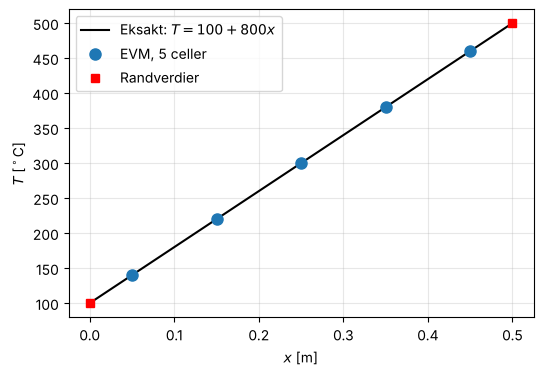

In [6]:
x_fin = np.linspace(0, L, 200)
plt.figure(figsize=(6, 4))
plt.plot(x_fin, T_eksakt(x_fin), "k-", label="Eksakt: $T=100+800x$")
plt.plot(noder, T, "o", ms=8, label="EVM, 5 celler")
plt.plot([0, L], [T_V, T_H], "rs", label="Randverdier")
plt.xlabel("$x$ [m]"); plt.ylabel(r"$T$ [$^\circ$C]")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

## 5. En generell funksjon

Vi samler alt i en funksjon som tar antall celler og randtemperaturene. For å kunne bruke den senere tar den også en varmeledningsevne som kan variere langs staven (en funksjon av $x$), og en regel for hvordan $\kappa$ på en flate regnes ut fra verdiene i de to nabonodene.

Kompendiet bruker **aritmetisk middel**, $\kappa_e = (\kappa_P+\kappa_E)/2$. For konstant $\kappa$ spiller valget ingen rolle.

In [7]:
def evm_1d(L, N, kappa_func, A, T_V, T_H, middel="aritmetisk"):
    '''Endelig volum-metode for d/dx(kappa dT/dx) = 0 på [0, L] med
    kjente randtemperaturer T_V (venstre) og T_H (høyre).
    kappa_func(x) gir varmeledningsevnen i punktet x.
    Returnerer (noder, T, flater).'''
    dx = L / N
    flater = np.linspace(0, L, N + 1)
    noder = 0.5 * (flater[:-1] + flater[1:])
    k = kappa_func(noder)                      # kappa i nodene

    # kappa på de indre flatene, fra de to nabonodene
    if middel == "aritmetisk":
        k_flate = 0.5 * (k[:-1] + k[1:])
    elif middel == "harmonisk":
        k_flate = 2 * k[:-1] * k[1:] / (k[:-1] + k[1:])
    else:
        raise ValueError("middel må være 'aritmetisk' eller 'harmonisk'")

    aW = np.zeros(N); aE = np.zeros(N); Su = np.zeros(N); Sp = np.zeros(N)
    aW[1:] = k_flate * A / dx      # celle i kobles til i-1 gjennom flate i
    aE[:-1] = k_flate * A / dx     # celle i kobles til i+1 gjennom flate i+1

    # randcellene: halv celle mot randen, kappa fra randcellens node
    Su[0] += 2 * k[0] * A / dx * T_V;   Sp[0] += -2 * k[0] * A / dx
    Su[-1] += 2 * k[-1] * A / dx * T_H; Sp[-1] += -2 * k[-1] * A / dx

    aP = aW + aE - Sp
    M = np.diag(aP) - np.diag(aW[1:], -1) - np.diag(aE[:-1], 1)
    T = np.linalg.solve(M, Su)
    return noder, T, flater

noder5, T5, _ = evm_1d(L, 5, lambda x: kappa * np.ones_like(x), A, T_V, T_H)
print(T5)

[140. 220. 300. 380. 460.]


## 6. Bevaring: den samme varmen strømmer gjennom hver flate

Uten varmekilde må like mye varme strømme gjennom *hver* flate i staven (ellers ville en celle samle opp eller miste varme). Varmefluksen i $x$-retning er $Q = -\kappa A\,\dfrac{dT}{dx}$; her er den eksakt
$$
Q = -\kappa A \cdot 800 = -8000 \text{ W},
$$
altså 8 kW fra den varme høyre enden mot den kalde venstre.

I EVM regner vi ut fluksen gjennom hver flate med *samme* formel som vi brukte da vi satte opp ligningene. La oss sjekke at den er lik på alle seks flatene -- også de to randflatene, der avstanden er $\delta x/2$.

In [8]:
def flukser(noder, T, flater, k_flate_indre, k_rand, A, T_V, T_H):
    '''Fluksen Q = -kappa*A*dT/dx gjennom hver av de N+1 flatene.'''
    dx = flater[1] - flater[0]
    Q = np.zeros(len(flater))
    Q[1:-1] = -k_flate_indre * A * (T[1:] - T[:-1]) / dx          # indre flater
    Q[0]  = -k_rand[0]  * A * (T[0] - T_V) / (dx / 2)              # venstre rand
    Q[-1] = -k_rand[1]  * A * (T_H - T[-1]) / (dx / 2)             # høyre rand
    return Q

Q = flukser(noder5, T5, flater, kappa * np.ones(4), (kappa, kappa), A, T_V, T_H)
for xf, q in zip(flater, Q):
    print(f"Flate x = {xf:.2f} m:  Q = {q:8.1f} W")

Flate x = 0.00 m:  Q =  -8000.0 W
Flate x = 0.10 m:  Q =  -8000.0 W
Flate x = 0.20 m:  Q =  -8000.0 W
Flate x = 0.30 m:  Q =  -8000.0 W
Flate x = 0.40 m:  Q =  -8000.0 W
Flate x = 0.50 m:  Q =  -8000.0 W


Alle flatene har samme fluks, $-8000$ W. Det er dette som menes med at EVM er **konservativ**: fluksen ut av én celle er *per konstruksjon* fluksen inn i nabocellen, så det som går inn i venstre ende kommer ut i høyre -- ingenting forsvinner eller oppstår underveis, uansett hvor grovt gitteret er.

## 7. Utblikk: en stav av to materialer

For konstant $\kappa$ gir EVM og endelige differanser de samme ligningene i de indre nodene (se bemerkningen i kompendiet). Fordelen med EVM viser seg når $\kappa$ *varierer*. Tenk deg en vegg av to lag: venstre halvdel har $\kappa_1 = 1000$ W/(m K), høyre halvdel $\kappa_2 = 100$ W/(m K).

Den eksakte løsningen er stykkevis lineær. Varmen må passere begge lagene etter hverandre, akkurat som strøm gjennom to seriekoblede motstander:
$$
Q = -\frac{T_H - T_V}{R_1 + R_2}, \qquad R_j = \frac{L/2}{\kappa_j A}.
$$

Eksakt fluks: Q = -1454.5 W, grensetemperatur 136.36 C
Maks feil, aritmetisk middel: 23.48015138094854
Maks feil, harmonisk middel:  1.1368683772161603e-13


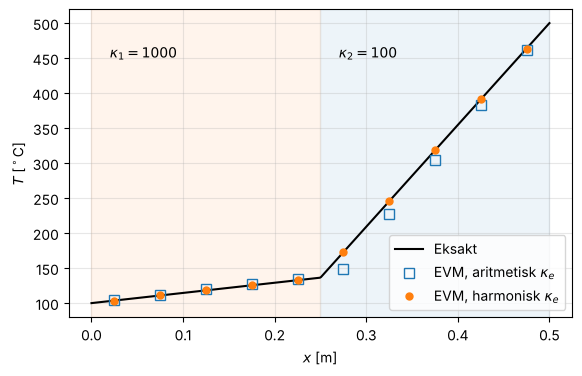

In [9]:
k1, k2 = 1000.0, 100.0
kappa_to = lambda x: np.where(x < L / 2, k1, k2)

R1 = (L / 2) / (k1 * A); R2 = (L / 2) / (k2 * A)
Q_eks = -(T_H - T_V) / (R1 + R2)
T_grense = T_V - Q_eks * R1            # temperaturen i grenseflaten x = L/2
def T_to_eksakt(x):
    return np.where(x < L / 2,
                    T_V + (T_grense - T_V) * x / (L / 2),
                    T_grense + (T_H - T_grense) * (x - L / 2) / (L / 2))

N = 10   # partall, slik at grenseflaten x = L/2 er en celleflate
x_a, T_a, fl = evm_1d(L, N, kappa_to, A, T_V, T_H, middel="aritmetisk")
x_h, T_h, _  = evm_1d(L, N, kappa_to, A, T_V, T_H, middel="harmonisk")

print(f"Eksakt fluks: Q = {Q_eks:.1f} W, grensetemperatur {T_grense:.2f} C")
print("Maks feil, aritmetisk middel:", np.max(np.abs(T_a - T_to_eksakt(x_a))))
print("Maks feil, harmonisk middel: ", np.max(np.abs(T_h - T_to_eksakt(x_h))))

xx = np.linspace(0, L, 400)
plt.figure(figsize=(6.5, 4))
plt.axvspan(0, L/2, color="tab:orange", alpha=0.08); plt.axvspan(L/2, L, color="tab:blue", alpha=0.08)
plt.plot(xx, T_to_eksakt(xx), "k-", label="Eksakt")
plt.plot(x_a, T_a, "s", ms=7, mfc="none", label=r"EVM, aritmetisk $\kappa_e$")
plt.plot(x_h, T_h, "o", ms=5, label=r"EVM, harmonisk $\kappa_e$")
plt.text(0.02, 450, r"$\kappa_1=1000$"); plt.text(0.27, 450, r"$\kappa_2=100$")
plt.xlabel("$x$ [m]"); plt.ylabel(r"$T$ [$^\circ$C]"); plt.legend(loc="lower right"); plt.grid(alpha=0.3)
plt.show()

Med aritmetisk middel blir det en feil rundt grenseflaten. Med **harmonisk middel**,
$$
\kappa_e = \frac{2\kappa_P\kappa_E}{\kappa_P+\kappa_E},
$$
blir løsningen eksakt. Grunnen er at fluksen mellom $P$ og $E$ må gjennom to halve celler med ulik ledningsevne -- to seriekoblede «varmemotstander» $\frac{\delta x/2}{\kappa_P A}$ og $\frac{\delta x/2}{\kappa_E A}$ -- og summen av dem gir nettopp det harmoniske middelet. Dette er typisk for EVM: når vi tenker i *flukser over flater*, får vi et naturlig svar på hvordan materialegenskapene skal håndteres.

(Vi kommer tilbake til variabel $\kappa$ senere. Til vanlig holder det med aritmetisk middel, som i kompendiet.)

## Prøv selv

1. Øk antall celler $N$ i stav-eksempelet. Er løsningen fortsatt eksakt? Hvorfor?
2. Bytt om randtemperaturene ($T_V = 500$, $T_H=100$). Hva skjer med fortegnet til fluksen $Q$?
3. Bruk $N=9$ (oddetall) for staven av to materialer. Nå ligger grenseflaten *midt i* en celle. Hvordan går det med de to middelverdiene da?
4. Skriv om `evm_1d` slik at den også tar et kildeledd (konstante $S^u$ og $S_P$ per celle). Det er utgangspunktet for F24.

## Oppsummering

* EVM: del området i celler, integrer ligningen over hver celle, og skriv om volumintegralet av divergensen til flukser over celleflatene (divergenssetningen).
* Tilnærm fluksene lineært mellom nodene. Det gir $a_P T_P = a_W T_W + a_E T_E + S^u$ med $a_P = a_W + a_E - S_P$.
* Randverdier: halv celle mot randen; kutt koblingen og legg randbidraget inn i $S^u$ og $S_P$.
* Metoden er konservativ: fluksen ut av én celle er fluksen inn i neste.